<a href="https://colab.research.google.com/github/Kauustubbh/DocForgery/blob/main/notebooks/03_evaluation_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cell 1: Environment Setup, Drive Mount & Dependencies
Installs segmentation-models-pytorch, mounts your Google Drive, verifies GPU availability, and ensures local scratchpad data paths exist.

In [1]:
# Cell 1: Environment Setup, Drive Mount & Dependencies
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/DocForgery'
PROCESSED_DIR = os.path.join(PROJECT_DIR, 'processed')
CHECKPOINTS_DIR = os.path.join(PROJECT_DIR, 'checkpoints')

# 2. Install segmentation models library
!pip install -q segmentation-models-pytorch

# 3. Verify hardware accelerator
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Execution Target: {device}")
if device.type == 'cuda':
    print(f"   Active GPU: {torch.cuda.get_device_name(0)}")

# 4. Confirm data scratchpad
if not os.path.exists('data/CASIA2'):
    print("Notice: Restoring CASIA 2.0 dataset scratchpad...")
    !kaggle datasets download -d sophatvathana/casia-dataset --unzip -p data/
if not os.path.exists('data/CASIA2_Groundtruth'):
    !git clone --depth 1 https://github.com/namtpham/casia2groundtruth.git data/casia2_gt
    !unzip -q data/casia2_gt/CASIA2.0_Groundtruth.zip -d data/CASIA2_Groundtruth/

print("✅ Environment and storage linked successfully.")

Mounted at /content/drive
✅ Execution Target: cuda
   Active GPU: Tesla T4
Notice: Restoring CASIA 2.0 dataset scratchpad...
Dataset URL: https://www.kaggle.com/datasets/sophatvathana/casia-dataset
License(s): unknown
100% 5.22G/5.22G [01:03<00:00, 87.8MB/s]

Cloning into 'data/casia2_gt'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 4.26 MiB | 22.75 MiB/s, done.
Resolving deltas: 100% (1/1), done.
✅ Environment and storage linked successfully.


## Cell 2: Ingest Test & Validation Partitions from metadata.csv
Loads the split contract from Google Drive, isolating the val split for threshold calibration and the held-out test split for the final benchmark.

In [2]:
# Cell 2: Ingest Splits from metadata.csv
import os
import pandas as pd

# Load master metadata manifest from Drive
manifest_path = os.path.join(PROCESSED_DIR, 'metadata.csv')
assert os.path.exists(manifest_path), f"Missing manifest at: {manifest_path}"
df = pd.read_csv(manifest_path)

val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f"✅ Split contract ingested from: {manifest_path}")
print(f"   - Validation Samples: {len(val_df)} (Authentic: {(val_df['label'] == 0).sum()}, Tampered: {(val_df['label'] == 1).sum()})")
print(f"   - Test Samples:       {len(test_df)} (Authentic: {(test_df['label'] == 0).sum()}, Tampered: {(test_df['label'] == 1).sum()})")

✅ Split contract ingested from: /content/drive/MyDrive/DocForgery/processed/metadata.csv
   - Validation Samples: 450 (Authentic: 225, Tampered: 225)
   - Test Samples:       450 (Authentic: 225, Tampered: 225)


## Cell 3: Load Pretrained U-Net Weights & Build Evaluation DataLoader
Instantiates the ResNet-34 U-Net architecture, loads the trained checkpoint best_unet.pth from Google Drive, sets the model to evaluation mode (model.eval()), and configures the deterministic evaluation data loader.

In [3]:
# Cell 3: Load Pretrained Weights & Evaluation Pipeline
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms.functional as TF
import segmentation_models_pytorch as smp

# 1. Deterministic Evaluation Transform (Resize 256x256 + ImageNet Normalization)
class EvalTransform:
    def __init__(self, size=(256, 256)):
        self.size = size

    def __call__(self, img: Image.Image, mask: Image.Image):
        img = TF.resize(img, self.size, interpolation=TF.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, self.size, interpolation=TF.InterpolationMode.NEAREST)

        img_tensor = TF.to_tensor(img)
        img_tensor = TF.normalize(img_tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        mask_np = np.array(mask, dtype=np.float32)
        if mask_np.ndim == 3:
            mask_np = mask_np[:, :, 0]
        mask_tensor = torch.from_numpy((mask_np > 128).astype(np.float32)).unsqueeze(0)

        return img_tensor, mask_tensor

class DocForgeryEvalDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, transform: EvalTransform):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')

        if pd.notnull(row['mask_path']) and os.path.exists(str(row['mask_path'])):
            mask = Image.open(row['mask_path']).convert('L')
        else:
            w, h = image.size
            mask = Image.new('L', (w, h), 0)

        img_tensor, mask_tensor = self.transform(image, mask)
        label = torch.tensor(row['label'], dtype=torch.float32)

        return img_tensor, mask_tensor, label, row['image_id'], row['forgery_full']

# 2. Build DataLoaders
eval_transform = EvalTransform(size=(256, 256))
val_loader = DataLoader(DocForgeryEvalDataset(val_df, eval_transform), batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(DocForgeryEvalDataset(test_df, eval_transform), batch_size=16, shuffle=False, num_workers=2)

# 3. Load Trained U-Net Model
checkpoint_path = os.path.join(CHECKPOINTS_DIR, 'best_unet.pth')
assert os.path.exists(checkpoint_path), f"Missing checkpoint file: {checkpoint_path}"

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model = model.to(device)
model.eval()

print(f"✅ Loaded weights from: {checkpoint_path}")
print(f"✅ Model set to evaluation mode on {device}.")

✅ Loaded weights from: /content/drive/MyDrive/DocForgery/checkpoints/best_unet.pth
✅ Model set to evaluation mode on cuda.


## Cell 4: Optimal Decision Threshold Sweep ($\tau \in [0.1, 0.9]$)
In Notebook 02, the model trained with pos_weight=10.0, elevating output probabilities to penalize missing forged regions. This cell evaluates the validation set across thresholds from $0.10$ to $0.90$ to locate the exact threshold $\tau^*$ that maximizes the Tampered Dice score while preventing false alarms on authentic documents.

🔍 Running validation inference for threshold calibration...

--- Threshold Sweep Results ---
 threshold  tampered_dice  precision  recall  auth_false_alarm_pct
    0.1000         0.1405     0.0904  0.9288               63.1489
    0.1500         0.1479     0.1002  0.7970               35.5511
    0.2000         0.1597     0.1131  0.7066               23.5120
    0.2500         0.1703     0.1289  0.6378               17.5384
    0.3000         0.1755     0.1404  0.5750               13.6405
    0.3500         0.1794     0.1486  0.5304               10.7047
    0.4000         0.1850     0.1694  0.4908                8.4484
    0.4500         0.1912     0.1956  0.4453                6.4752
    0.5000         0.1946     0.2220  0.4083                5.0390
    0.5500         0.1985     0.2724  0.3785                3.9994
    0.6000         0.1987     0.3200  0.3477                3.1654
    0.6500         0.1939     0.3792  0.3140                2.5163
    0.7000         0.1887     0.4476

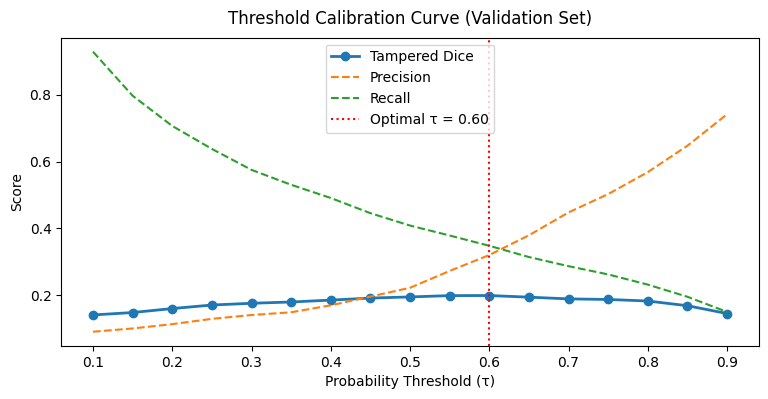

In [4]:
# Validation Optimal Threshold Sweep
import numpy as np
import matplotlib.pyplot as plt

print("🔍 Running validation inference for threshold calibration...")

val_probs = []
val_masks = []
val_labels = []

# Collect predictions across the validation set
with torch.no_grad():
    for images, masks, labels, _, _ in val_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu()

        val_probs.append(probs)
        val_masks.append(masks)
        val_labels.append(labels)

val_probs = torch.cat(val_probs, dim=0)  # Shape: [N, 1, 256, 256]
val_masks = torch.cat(val_masks, dim=0)  # Shape: [N, 1, 256, 256]
val_labels = torch.cat(val_labels, dim=0) # Shape: [N]

thresholds = np.linspace(0.10, 0.90, 17)
sweep_results = []

for thresh in thresholds:
    preds = (val_probs > thresh).float()

    tampered_dices = []
    tampered_precisions = []
    tampered_recalls = []
    auth_false_alarm_rates = []

    for i in range(len(val_labels)):
        inter = (preds[i] * val_masks[i]).sum().item()
        pred_pos = preds[i].sum().item()
        true_pos = val_masks[i].sum().item()

        if val_labels[i] == 1.0:
            # Tampered image metrics
            union = pred_pos + true_pos
            dice = (2.0 * inter + 1e-6) / (union + 1e-6)
            prec = (inter + 1e-6) / (pred_pos + 1e-6)
            rec = (inter + 1e-6) / (true_pos + 1e-6)

            tampered_dices.append(dice)
            tampered_precisions.append(prec)
            tampered_recalls.append(rec)
        else:
            # Authentic image: False Alarm Rate (% of pixels falsely flagged as forged)
            false_alarm = pred_pos / (256 * 256)
            auth_false_alarm_rates.append(false_alarm)

    mean_dice = np.mean(tampered_dices)
    mean_prec = np.mean(tampered_precisions)
    mean_rec = np.mean(tampered_recalls)
    mean_false_alarm = np.mean(auth_false_alarm_rates) * 100.0

    sweep_results.append({
        'threshold': thresh,
        'tampered_dice': mean_dice,
        'precision': mean_prec,
        'recall': mean_rec,
        'auth_false_alarm_pct': mean_false_alarm
    })

sweep_df = pd.DataFrame(sweep_results)

# Optimal threshold maximizes Tampered Dice while controlling false alarm rate
optimal_idx = sweep_df['tampered_dice'].idxmax()
optimal_thresh = sweep_df.loc[optimal_idx, 'threshold']
optimal_dice = sweep_df.loc[optimal_idx, 'tampered_dice']

print("\n--- Threshold Sweep Results ---")
print(sweep_df.to_string(index=False, float_format="%.4f"))
print(f"\n⭐ Optimal Threshold: {optimal_thresh:.2f} (Peak Tampered Dice: {optimal_dice:.4f})")

# Plot threshold response curves
plt.figure(figsize=(9, 4))
plt.plot(sweep_df['threshold'], sweep_df['tampered_dice'], label='Tampered Dice', marker='o', linewidth=2)
plt.plot(sweep_df['threshold'], sweep_df['precision'], label='Precision', linestyle='--')
plt.plot(sweep_df['threshold'], sweep_df['recall'], label='Recall', linestyle='--')
plt.axvline(optimal_thresh, color='red', linestyle=':', label=f'Optimal τ = {optimal_thresh:.2f}')
plt.title('Threshold Calibration Curve (Validation Set)', fontsize=12, pad=10)
plt.xlabel('Probability Threshold (τ)')
plt.ylabel('Score')
plt.legend()
plt.show()

## Cell 5: Benchmark on Unseen Test Set (Pixel & Image Levels)
Evaluates the held-out test set at the calibrated threshold $\tau^*$. Computes both:Pixel-Level Localization: Dice, IoU (Jaccard Index), Precision, and Recall on tampered documents.Image-Level Classification: Determines whether each document is clean or forged based on detected area, outputting a Confusion Matrix, Accuracy, and ROC-AUC.

📊 Benchmarking on Unseen Test Set using Optimal Threshold (τ = 0.60)...

        TEST SET EVALUATION SCORECARD
--- Pixel-Level Localization (Tampered Only) ---
  Tampered Dice Score:      0.2160
  Tampered IoU (Jaccard):   0.1572
  Pixel Precision:          0.3807
  Pixel Recall:             0.3640

--- Image-Level Forgery Detection ---
  Image Classification AUC: 0.7742
  Image Accuracy:           68.22%

              precision    recall  f1-score   support

   Authentic       0.77      0.52      0.62       225
    Tampered       0.64      0.84      0.73       225

    accuracy                           0.68       450
   macro avg       0.70      0.68      0.67       450
weighted avg       0.70      0.68      0.67       450



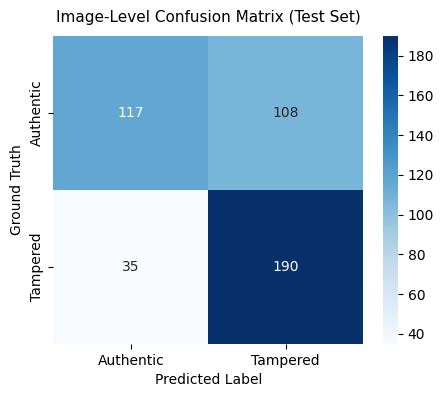

In [5]:
# Unseen Test Set Evaluation Benchmark
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import seaborn as sns

print(f"📊 Benchmarking on Unseen Test Set using Optimal Threshold (τ = {optimal_thresh:.2f})...\n")

test_probs = []
test_masks = []
test_labels = []

with torch.no_grad():
    for images, masks, labels, _, _ in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu()

        test_probs.append(probs)
        test_masks.append(masks)
        test_labels.append(labels)

test_probs = torch.cat(test_probs, dim=0)
test_masks = torch.cat(test_masks, dim=0)
test_labels = torch.cat(test_labels, dim=0)

# Binary pixel segmentation at optimal threshold
test_preds = (test_probs > optimal_thresh).float()

# 1. Pixel-Level Metrics (Tampered samples only)
tampered_dices = []
tampered_ious = []
tampered_precisions = []
tampered_recalls = []

for i in range(len(test_labels)):
    if test_labels[i] == 1.0:
        inter = (test_preds[i] * test_masks[i]).sum().item()
        p_sum = test_preds[i].sum().item()
        t_sum = test_masks[i].sum().item()

        dice = (2.0 * inter + 1e-6) / (p_sum + t_sum + 1e-6)
        iou = (inter + 1e-6) / (p_sum + t_sum - inter + 1e-6)
        prec = (inter + 1e-6) / (p_sum + 1e-6)
        rec = (inter + 1e-6) / (t_sum + 1e-6)

        tampered_dices.append(dice)
        tampered_ious.append(iou)
        tampered_precisions.append(prec)
        tampered_recalls.append(rec)

# 2. Image-Level Classification (Flag tampered if forged region >= 50 pixels)
AREA_THRESHOLD_PIXELS = 50
pred_labels = []
max_probs_per_image = []

for i in range(len(test_labels)):
    pred_area = test_preds[i].sum().item()
    pred_labels.append(1 if pred_area >= AREA_THRESHOLD_PIXELS else 0)
    max_probs_per_image.append(test_probs[i].max().item())

pred_labels = np.array(pred_labels)
true_labels = test_labels.numpy().astype(int)
roc_auc = roc_auc_score(true_labels, max_probs_per_image)

print("="*55)
print("        TEST SET EVALUATION SCORECARD")
print("="*55)
print("--- Pixel-Level Localization (Tampered Only) ---")
print(f"  Tampered Dice Score:      {np.mean(tampered_dices):.4f}")
print(f"  Tampered IoU (Jaccard):   {np.mean(tampered_ious):.4f}")
print(f"  Pixel Precision:          {np.mean(tampered_precisions):.4f}")
print(f"  Pixel Recall:             {np.mean(tampered_recalls):.4f}")
print("\n--- Image-Level Forgery Detection ---")
print(f"  Image Classification AUC: {roc_auc:.4f}")
print(f"  Image Accuracy:           {np.mean(pred_labels == true_labels)*100:.2f}%\n")
print(classification_report(true_labels, pred_labels, target_names=['Authentic', 'Tampered']))

# Plot Confusion Matrix
cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Authentic', 'Tampered'], yticklabels=['Authentic', 'Tampered'])
plt.title(f'Image-Level Confusion Matrix (Test Set)', fontsize=11, pad=10)
plt.xlabel('Predicted Label')
plt.ylabel('Ground Truth')
plt.show()

## Cell 6: Forensic Visual Inspection & Qualitative Overlays
Extracts representative test samples (Authentic, Spliced, and Copy-Move) and renders a 4-column forensic inspection panel:

Original Document

Ground-Truth Mask

Model Tampering Probability Heatmap (color intensity denotes forgery confidence)

Translucent Red Overlay on Detected Forgeries

🎨 Displaying Qualitative Forensic Evaluation Panels...


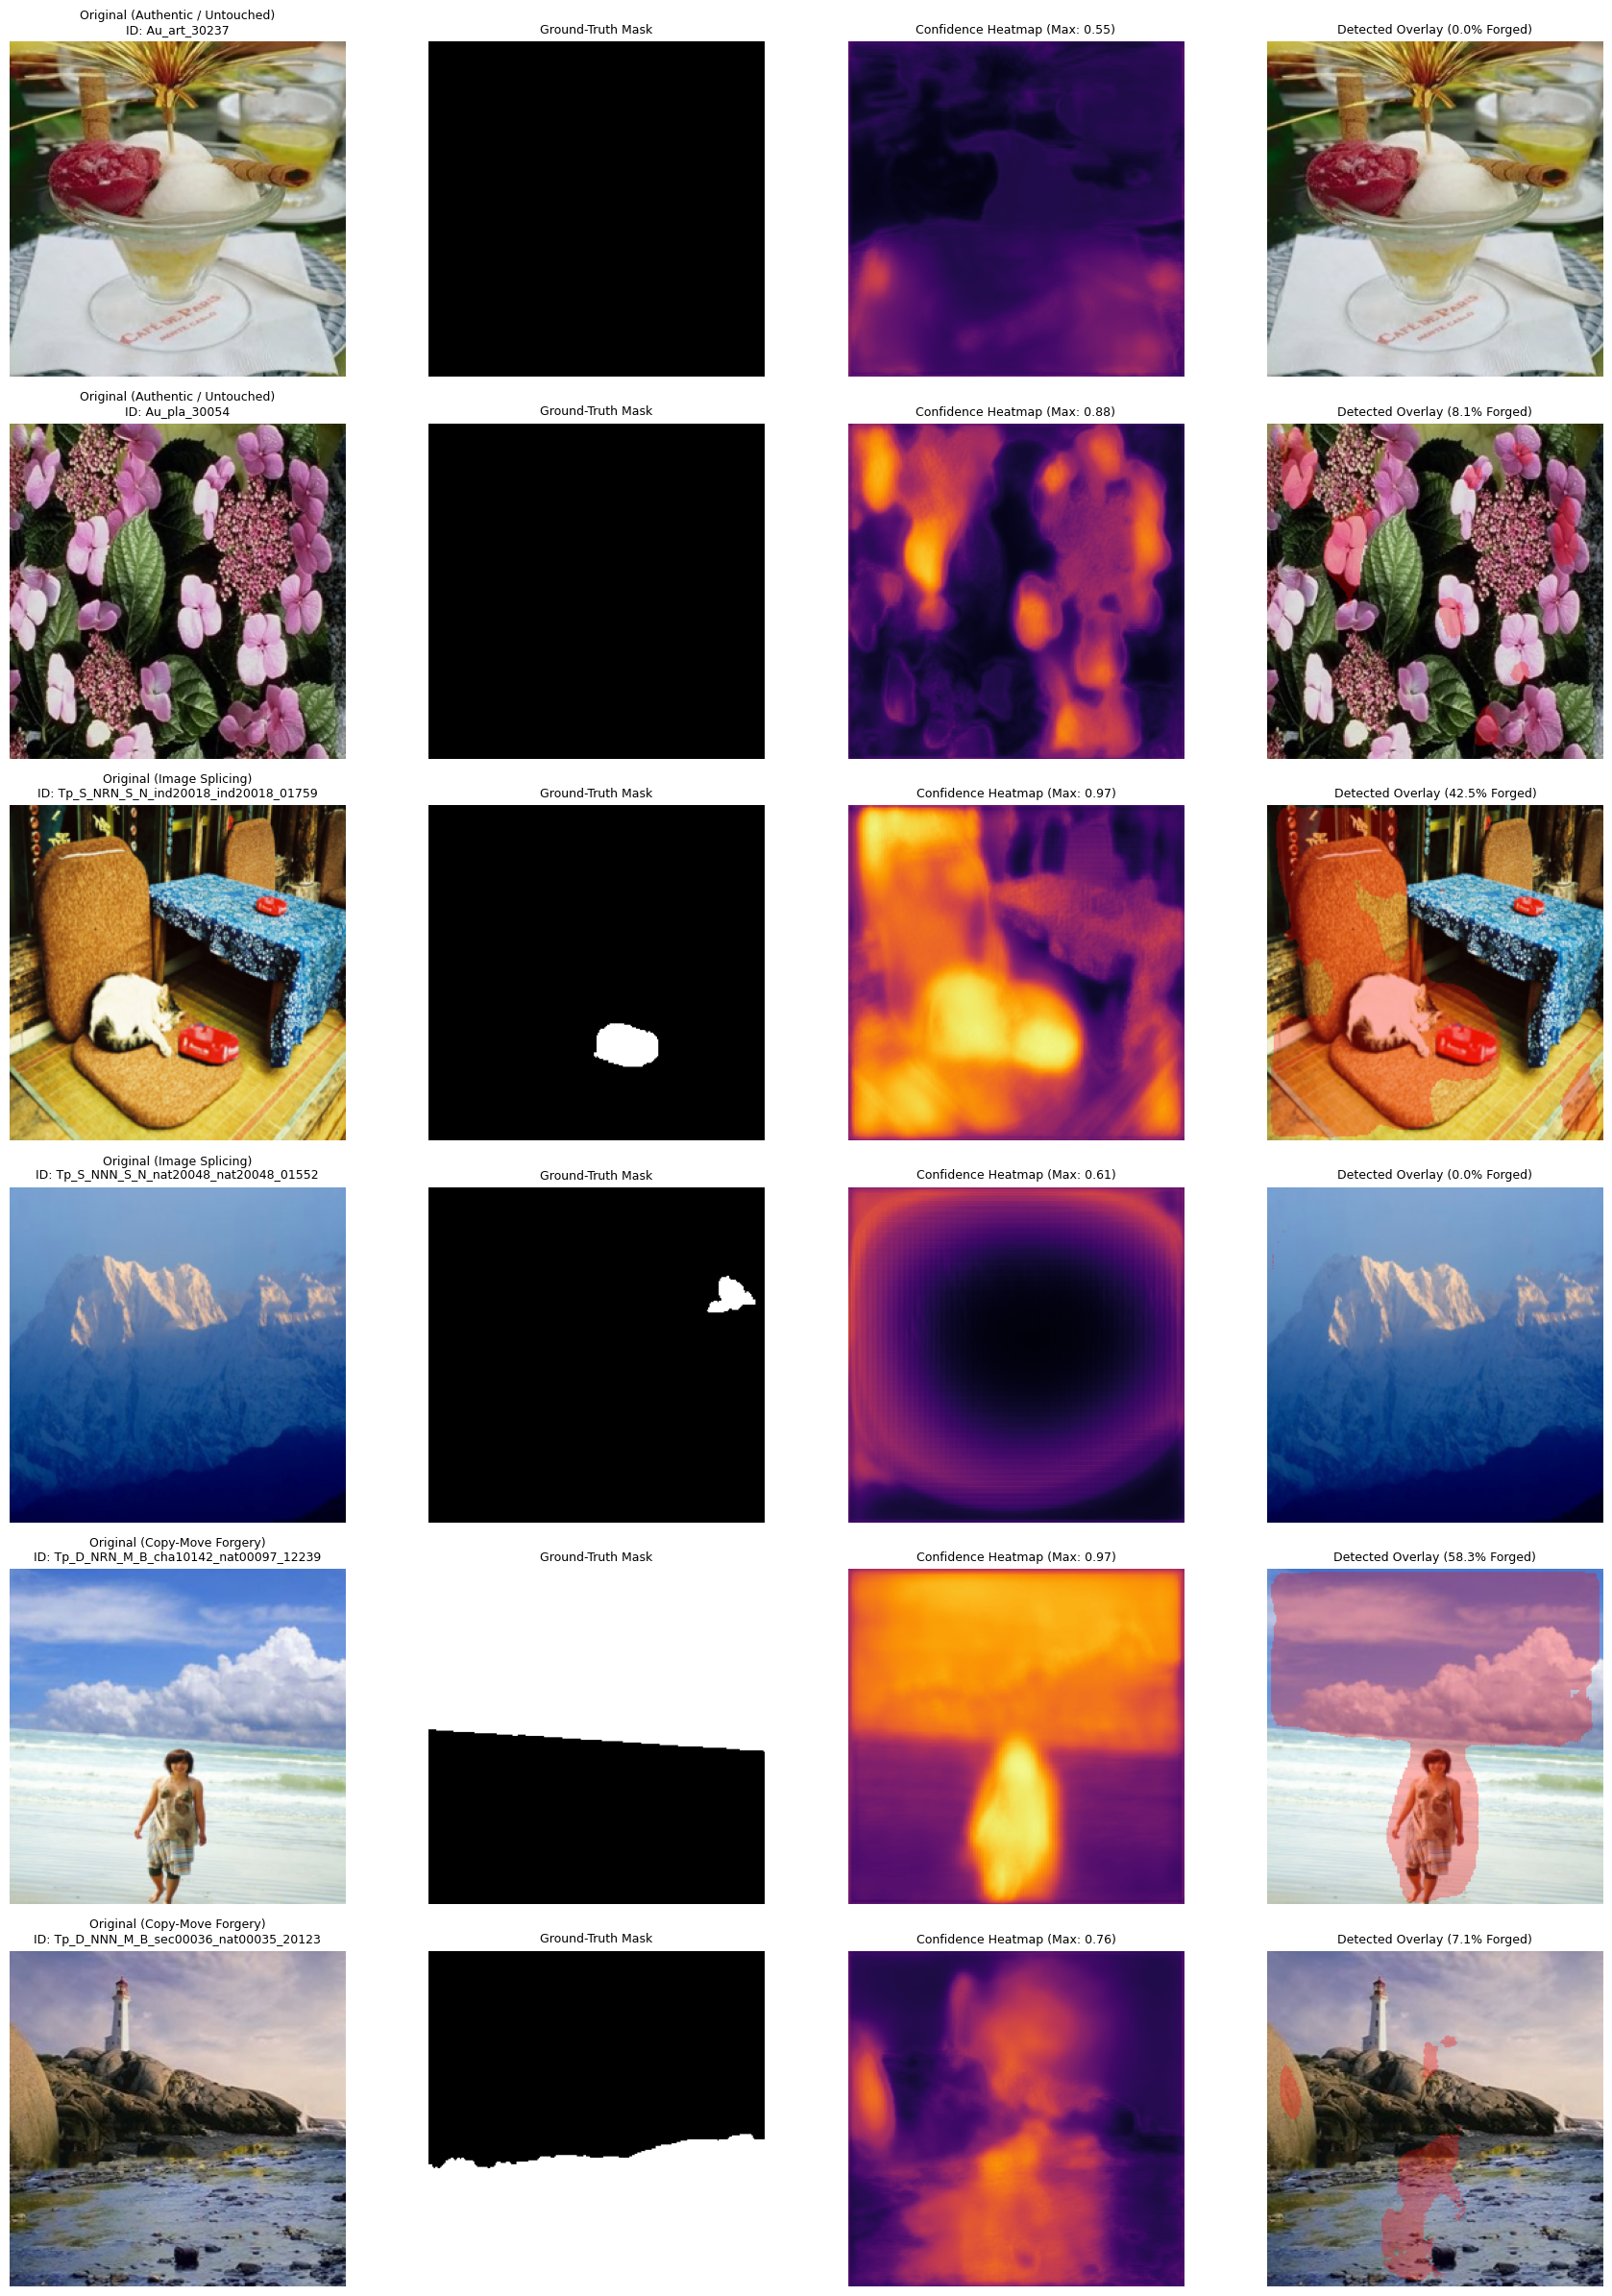

In [6]:
# Qualitative Visual Inspection Panel
def visualize_forensic_results(indices):
    fig, axes = plt.subplots(len(indices), 4, figsize=(18, 4 * len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, idx in enumerate(indices):
        img_t, mask_t, label, img_id, forgery_type = test_loader.dataset[idx]

        # De-normalize RGB tensor to [0, 255] image
        img_np = img_t.cpu().permute(1, 2, 0).numpy()
        img_np = (img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]))
        img_np = np.clip(img_np * 255.0, 0, 255).astype(np.uint8)

        gt_mask = (mask_t[0].cpu().numpy() * 255.0).astype(np.uint8)

        # Model probability and binary prediction
        with torch.no_grad():
            prob_map = torch.sigmoid(model(img_t.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        pred_mask = (prob_map > optimal_thresh).astype(np.uint8) * 255

        # Red translucent overlay on detected regions
        overlay = img_np.copy()
        overlay[pred_mask > 0] = [255, 0, 0]
        blended = cv2.addWeighted(img_np, 0.7, overlay, 0.3, 0)

        forged_area_pct = (pred_mask > 0).sum() / (256 * 256) * 100.0

        # Plot 4-column panel
        axes[row_idx, 0].imshow(img_np)
        axes[row_idx, 0].set_title(f"Original ({forgery_type})\nID: {img_id}", fontsize=9)

        axes[row_idx, 1].imshow(gt_mask, cmap='gray')
        axes[row_idx, 1].set_title("Ground-Truth Mask", fontsize=9)

        im = axes[row_idx, 2].imshow(prob_map, cmap='inferno', vmin=0.0, vmax=1.0)
        axes[row_idx, 2].set_title(f"Confidence Heatmap (Max: {prob_map.max():.2f})", fontsize=9)

        axes[row_idx, 3].imshow(blended)
        axes[row_idx, 3].set_title(f"Detected Overlay ({forged_area_pct:.1f}% Forged)", fontsize=9)

        for col in range(4):
            axes[row_idx, col].axis('off')

    plt.tight_layout()
    plt.show()

# Sample 2 Authentic, 2 Splicing, and 2 Copy-Move documents from Test Set
test_df_indexed = test_loader.dataset.df
auth_indices = test_df_indexed[test_df_indexed['label'] == 0].index[:2].tolist()
splicing_indices = test_df_indexed[test_df_indexed['forgery_type'] == 'splicing'].index[:2].tolist()
copymove_indices = test_df_indexed[test_df_indexed['forgery_type'] == 'copy_move'].index[:2].tolist()

sample_indices = auth_indices + splicing_indices + copymove_indices

print("🎨 Displaying Qualitative Forensic Evaluation Panels...")
visualize_forensic_results(sample_indices)